# Desigualdad de oportunidades en matemáticas

**Pregunta:** ¿qué parte de la desigualdad de puntajes en matemáticas se explica por **circunstancias de origen** que el estudiante no eligió? ¿Cómo está Ecuador frente a América Latina, la OCDE y lo que se medía en 2006?

**Referencia:** Ferreira, F. y Gignoux, J. (2014). *The Measurement of Educational Inequality: Achievement and Opportunity*. **World Bank Economic Review**, 28(2), 210–246.

## 0. Qué reutilizamos del notebook 01 - EDA

**No volvemos a convertir nada.** Los parquet de `datos/` ya existen. De `01_conversion_brechas` reutilizamos:
- las **rutas** y la lectura de parquet con `columns` y `filters`;
- los nombres de **PV**, **peso** y **80 réplicas**;
- la lógica de `estimar` (10 PV + 80 réplicas → valor + error estándar).

Como cada notebook tiene su propia memoria, esas pocas líneas se vuelven a definir aquí (son segundos).

## 1. Librerías

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Rutas, países y columnas

Esta vez leemos **los 90 participantes** (no solo América Latina + OCDE): en el notebook siguiente haremos clusters de países y conviene tener todos.

In [2]:
CARPETA_PISA = Path.cwd()
if not (CARPETA_PISA / "datos").exists():
    CARPETA_PISA = CARPETA_PISA.parent          # si el notebook está en /scripts
DATOS = CARPETA_PISA / "datos"
SALIDA = DATOS / "resultados"
SALIDA.mkdir(exist_ok=True)

LATAM = ["ARG", "BRA", "CHL", "COL", "CRI", "DOM", "ECU",
         "GTM", "MEX", "PER", "PRY", "SLV", "URY"]

PV   = [f"PV{i}MATH" for i in range(1, 11)]     # 10 valores plausibles
PESO = "W_FSTUWT"                               # peso final
REPS = [f"W_FSTURWT{r}" for r in range(1, 81)]  # 80 pesos replicados

## 3. Las 10 circunstancias: de 2006 a 2025

Ferreira y Gignoux usan 10 circunstancias (págs. 217–218 del paper). Buscamos su equivalente en PISA 2025:

| # | Paper (PISA 2006) | PISA 2025 | Categorías que usamos |
| --- | --- | --- | --- |
| 1 | Sexo | `MALE` | hombre / mujer |
| 2 | Educación del padre | `P1ISCED` (padre/tutor 1) | ≤ básica · bachillerato · post-sec./técnico · universitaria |
| 3 | Educación de la madre | `P2ISCED` (padre/tutor 2) | ídem |
| 4 | Ocupación del padre | `OCOP1` (padre/tutor 1, ISCO) | alta calificación · media · manual/elemental · no trabaja |
| 5 | Idioma en casa ≠ prueba | `ST022Q01TA` | sí / no |
| 6 | Migración | `IMMIG` | nativo / migrante (1.ª o 2.ª gen.) |
| 7 | Libros en casa | `ST255Q01JA` | 0–10 · 11–25 · 26–100 · más de 100 |
| 8 | Bienes del hogar | `ST250` (computadora, celular, internet), `ST254` (TV), `ST251` (auto) | tiene / no tiene (5 bienes) |
| 9 | Posesiones culturales | `ST251Q06JA` (instrumentos), `ST251Q07JA` (arte) | tiene / no tiene |
| 10 | Zona de la escuela | `SC001Q01TA` (base de escuelas) | rural · pueblo · ciudad |

**Diferencias con 2006:**
- En 2025 PISA pregunta por "padre/tutor 1 y 2", no por padre y madre.
- Quitamos el **lavavajillas**: no se preguntó en Ecuador ni Colombia.

**Datos faltantes:** como en el paper, cada circunstancia tiene una categoría **"faltante"**. Así **no perdemos estudiantes** (Ferreira y Gignoux codifican los faltantes de los padres como "sin educación o desconocido").

In [3]:
CIRC = ["MALE", "P1ISCED", "P2ISCED", "OCOP1", "ST022Q01TA", "IMMIG", "ST255Q01JA",
        "ST250Q02JA", "ST250Q04JA", "ST250Q05JA", "ST254Q01JA", "ST251Q01JA",
        "ST251Q06JA", "ST251Q07JA"]

COLUMNAS = ["CNT", "CNTSCHID", "OECD"] + CIRC + PV + [PESO] + REPS
len(COLUMNAS)

108

## 4. Leer los datos

* Leemos estudiantes (90 participantes) y les pegamos la zona desde la base de escuelas, igual que en el notebook 01. Pasamos a `float32` para ahorrar memoria.
* De los parquet carga solo las 108 columnas de COLUMNAS (circunstancias, 10 PV, peso y réplicas) para los 90 participantes, no las 885.

In [ ]:
# ¿Qué país se pierde con el filtro de PV y peso? Uzbekistán
tmp = pd.read_parquet(DATOS / "estudiantes", columns=["CNT", PESO] + PV)
tmp["CNT"] = tmp["CNT"].astype(str)
tmp["sin_pv"]   = tmp[PV].isna().any(axis=1)
tmp["sin_peso"] = tmp[PESO].isna()

resumen = tmp.groupby("CNT")[["sin_pv", "sin_peso"]].mean().mul(100).round(1)
resumen[(resumen > 0).any(axis=1)].sort_values("sin_pv", ascending=False)

,sin_pv,sin_peso
CNT,,
UZB,100.0,0.0


* 747.068 estudiantes. Es la muestra final con la que se calcula el IOp (IOp = desigualdad de oportunidades (Inequality of Opportunity)): todos tienen los 10 puntajes de matemática y el peso. Antes había 755.721, así que salieron unos 8.650 estudiantes, casi todos de Uzbekistán (más, como mucho, el estudiante belga sin puntaje). Es apenas el 1,1 % de la muestra.
* 89 participantes. Son los 90 de PISA 2025 menos Uzbekistán. En adelante, todos los resultados son para estos 89.

In [4]:
inicio = time.time()
est = pd.read_parquet(DATOS / "estudiantes", columns=COLUMNAS)
est["CNT"] = est["CNT"].astype(str)
num = est.select_dtypes("float64").columns
est[num] = est[num].astype("float32")

esc = pd.read_parquet(DATOS / "escuelas", columns=["CNT", "CNTSCHID", "SC001Q01TA"])
esc["CNT"] = esc["CNT"].astype(str)
est = est.merge(esc, on=["CNT", "CNTSCHID"], how="left")

# Solo estudiantes con los 10 PV y peso (quita al estudiante de Bélgica sin puntaje)
est = est[est[PV].notna().all(axis=1) & est[PESO].notna()].reset_index(drop=True)

print(f"{len(est):,} estudiantes · {est['CNT'].nunique()} participantes · {time.time() - inicio:.0f} s")

747,068 estudiantes · 89 participantes · 15 s


## 5. Construir las circunstancias como categorías

Cada función toma una variable de PISA y devuelve su **categoría** en texto. Todo lo vacío queda como `"faltante"`.

In [6]:
def educ_padre(x):
    # ISCED de PISA: 1-2 = hasta básica · 3-4 = bachillerato · 5-6 = post-sec./técnico · 7-9 = universitaria
    return pd.Series(np.select([x <= 2, x <= 4, x <= 6, x <= 9],
                               ["1 ≤ básica", "2 bachillerato", "3 post-sec./técnico", "4 universitaria"],
                               "faltante"), index=x.index)


def ocupacion(x):
    # OCOP1 es texto (código ISCO). Primer dígito: 1-3 alta, 4-5 y 0 (FF.AA.) media, 6-9 manual.
    # "97" = códigos auxiliares PISA (hogar, desempleo…). "995"-"999" = no respuesta.
    x = x.astype(str).str.strip()
    d = x.str[0]
    return pd.Series(np.select(
        [x.str.len() >= 3, x == "97", d.isin(["1", "2", "3"]), d.isin(["4", "5", "0"]), d.isin(["6", "7", "8", "9"])],
        ["faltante", "4 no trabaja/otro", "1 alta calificación", "2 media", "3 manual/elemental"],
        "faltante"), index=x.index)


def si_no(condicion_si, x):
    return pd.Series(np.select([x.isna(), condicion_si], ["faltante", "sí"], "no"), index=x.index)


def libros(x):
    return pd.Series(np.select([x <= 2, x == 3, x == 4, x >= 5],
                               ["1 0-10", "2 11-25", "3 26-100", "4 más de 100"], "faltante"), index=x.index)


def zona(x):
    return pd.Series(np.select([x == 1, x <= 3, x <= 6], ["1 rural", "2 pueblo", "3 ciudad"], "faltante"),
                     index=x.index)


c = pd.DataFrame(index=est.index)
c["sexo"]        = si_no(est["MALE"] == 1, est["MALE"])                 # sí = hombre
c["educ_p1"]     = educ_padre(est["P1ISCED"])
c["educ_p2"]     = educ_padre(est["P2ISCED"])
c["ocup_p1"]     = ocupacion(est["OCOP1"])
c["idioma_otro"] = si_no(est["ST022Q01TA"] == 2, est["ST022Q01TA"])
c["migrante"]    = si_no(est["IMMIG"].isin([2, 3]), est["IMMIG"])
c["libros"]      = libros(est["ST255Q01JA"])
c["computadora"] = si_no(est["ST250Q02JA"] == 1, est["ST250Q02JA"])
c["celular"]     = si_no(est["ST250Q04JA"] == 1, est["ST250Q04JA"])
c["internet"]    = si_no(est["ST250Q05JA"] == 1, est["ST250Q05JA"])
c["tv"]          = si_no(est["ST254Q01JA"] >= 2, est["ST254Q01JA"])     # 2+ = al menos una
c["auto"]        = si_no(est["ST251Q01JA"] >= 2, est["ST251Q01JA"])
c["instrumento"] = si_no(est["ST251Q06JA"] >= 2, est["ST251Q06JA"])
c["arte"]        = si_no(est["ST251Q07JA"] >= 2, est["ST251Q07JA"])
c["zona"]        = zona(est["SC001Q01TA"])

c[c.index.isin(est.index[est["CNT"] == "ECU"])].apply(lambda s: s.value_counts(normalize=True).round(2).to_dict())

sexo                                      {'no': 0.5, 'sí': 0.5}
educ_p1        {'2 bachillerato': 0.44, '4 universitaria': 0....
educ_p2        {'faltante': 0.47, '2 bachillerato': 0.23, '4 ...
ocup_p1        {'3 manual/elemental': 0.41, '1 alta calificac...
idioma_otro           {'no': 0.97, 'sí': 0.02, 'faltante': 0.01}
migrante              {'no': 0.92, 'faltante': 0.06, 'sí': 0.02}
libros         {'1 0-10': 0.61, '2 11-25': 0.2, '3 26-100': 0...
computadora           {'sí': 0.66, 'no': 0.31, 'faltante': 0.03}
celular               {'sí': 0.86, 'no': 0.11, 'faltante': 0.03}
internet              {'sí': 0.85, 'no': 0.12, 'faltante': 0.03}
tv                    {'sí': 0.84, 'no': 0.09, 'faltante': 0.07}
auto                  {'sí': 0.52, 'no': 0.45, 'faltante': 0.03}
instrumento           {'no': 0.61, 'sí': 0.36, 'faltante': 0.03}
arte                  {'no': 0.49, 'sí': 0.48, 'faltante': 0.03}
zona           {'3 ciudad': 0.52, '2 pueblo': 0.37, '1 rural'...
dtype: object

### Agrupar las circunstancias como en el paper

Para la descomposición (sección 9) agrupamos las 15 columnas en las **10 circunstancias** del paper y en **5 familias** para el gráfico:

In [7]:
GRUPOS = {                       # circunstancia del paper → columnas
    "Sexo":                  ["sexo"],
    "Educación padre/tutor 1": ["educ_p1"],
    "Educación padre/tutor 2": ["educ_p2"],
    "Ocupación padre/tutor 1": ["ocup_p1"],
    "Idioma en casa":        ["idioma_otro"],
    "Migración":             ["migrante"],
    "Libros en casa":        ["libros"],
    "Bienes del hogar":      ["computadora", "celular", "internet", "tv", "auto"],
    "Posesiones culturales": ["instrumento", "arte"],
    "Zona de la escuela":    ["zona"],
}

FAMILIAS = {                     # para el gráfico: 5 familias
    "Padres (educación y ocupación)": ["Educación padre/tutor 1", "Educación padre/tutor 2", "Ocupación padre/tutor 1"],
    "Recursos del hogar (libros, bienes, cultura)": ["Libros en casa", "Bienes del hogar", "Posesiones culturales"],
    "Zona de la escuela": ["Zona de la escuela"],
    "Migración e idioma": ["Migración", "Idioma en casa"],
    "Sexo": ["Sexo"],
}

### Revisión: ¿alguna circunstancia falta por completo en algún país?

Si un país no tiene una circunstancia (100 % "faltante"), su IOp sale **más baja de lo real**: le falta información. Lo marcamos para tenerlo en cuenta.

In [8]:
pct_falt = (c.eq("faltante").groupby(est["CNT"]).mean() * 100).round(0)
pct_falt_grupo = pd.DataFrame({g: pct_falt[cols].max(axis=1) for g, cols in GRUPOS.items()})

incompletos = pct_falt_grupo[(pct_falt_grupo >= 95).any(axis=1)]
print("Países con alguna circunstancia ausente (≥ 95 % faltante):")
incompletos.loc[:, (incompletos >= 95).any()]

Países con alguna circunstancia ausente (≥ 95 % faltante):


,Educación padre/tutor 1,Educación padre/tutor 2,Ocupación padre/tutor 1,Migración,Libros en casa,Bienes del hogar,Posesiones culturales,Zona de la escuela
CNT,,,,,,,,
CAN,16.0,23.0,100.0,11.0,5.0,15.0,6.0,28.0
CRI,100.0,100.0,100.0,100.0,4.0,100.0,100.0,4.0
DEU,25.0,34.0,23.0,13.0,11.0,15.0,100.0,15.0
ISL,21.0,26.0,17.0,8.0,4.0,7.0,5.0,100.0
LUX,26.0,34.0,17.0,7.0,2.0,4.0,4.0,100.0
MAC,4.0,13.0,5.0,3.0,0.0,0.0,1.0,100.0
MLT,19.0,27.0,18.0,11.0,5.0,6.0,5.0,100.0
MUS,17.0,28.0,13.0,100.0,1.0,3.0,3.0,0.0
NLD,16.0,21.0,12.0,8.0,4.0,100.0,5.0,39.0


Cada fila es un país al que le falta al menos una circunstancia completa. Por ejemplo, **El Salvador** suprimió la educación de los padres, los libros y la zona (capítulo 13 del *Technical Report*). Su IOp estará **subestimada** y lo marcaremos.

## 6. Matriz de diseño: las circunstancias como números (dummies)

La regresión necesita números, no texto. Cada categoría se convierte en una columna de 0/1 (*dummies*). Se omite una categoría por variable (la de referencia) para evitar redundancia, y se agrega una columna de unos (el intercepto).

Guardamos qué columnas pertenecen a cada circunstancia para la descomposición.

In [9]:
X_df = pd.get_dummies(c, drop_first=True, dtype="float32")
X_df.insert(0, "intercepto", 1.0)

COLS_GRUPO = {g: [j for j, col in enumerate(X_df.columns)
                  if any(col.startswith(v + "_") for v in vars_)]
              for g, vars_ in GRUPOS.items()}

print(f"Matriz X: {X_df.shape[0]:,} estudiantes × {X_df.shape[1]} columnas")
X_all = X_df.to_numpy()

Matriz X: 747,068 estudiantes × 40 columnas


## 7. Las funciones de estimación

### 7.1 `r2_mco`: la IOp de Ferreira y Gignoux

Hace una regresión MCO **ponderada** del puntaje sobre las circunstancias y devuelve el **R²**, una vez por cada PV (los 10 a la vez):

```latex
\theta_{IOp} = R^2 = \frac{\mathrm{Var}(\hat{y})}{\mathrm{Var}(y)}
```

- `ŷ` = el puntaje que **predicen** las circunstancias.
- R² = qué parte de la variación de puntajes se explica por el origen.

Truco: multiplicar X e y por la raíz del peso convierte una MCO normal en una MCO **ponderada**.

### 7.2 `de`: la desigualdad de logro

La desviación estándar ponderada de los puntajes (también una vez por cada PV).

### 7.3 `estimar`: igual que en el notebook 01

Calcula cualquier estadístico con los **10 PV** y los **80 pesos replicados** → valor + error estándar. Es la misma lógica de antes, ahora para matrices.

In [10]:
def var_w(Y, w):
    # Varianza ponderada de cada columna de Y
    mu = (w @ Y) / w.sum()
    return (w @ (Y - mu) ** 2) / w.sum()


def r2_mco(X, Y, w):
    sw = np.sqrt(w)[:, None]
    beta = np.linalg.lstsq(X * sw, Y * sw, rcond=None)[0]   # coeficientes (uno por PV)
    return var_w(X @ beta, w) / var_w(Y, w)                  # 10 R²


def de(X, Y, w):
    return np.sqrt(var_w(Y, w))                              # 10 desviaciones estándar


def media(X, Y, w):
    return (w @ Y) / w.sum()


def estimar(X, Y, w, W, estadistico, con_se=True):
    est_pv = estadistico(X, Y, w)
    if not con_se:
        return est_pv.mean(), np.nan
    est_rep = np.array([estadistico(X, Y, W[:, r]) for r in range(W.shape[1])])
    var_muestreo = (0.05 * ((est_rep - est_pv) ** 2).sum(axis=0)).mean()
    var_medicion = (1 + 1 / 10) * est_pv.var(ddof=1)
    return est_pv.mean(), np.sqrt(var_muestreo + var_medicion)

### Prueba con Ecuador

Antes de correr los 90 países, probamos con uno. Mira el R²: es la primera estimación de desigualdad de oportunidades para Ecuador con este método.

In [11]:
def matrices(pais):
    fila = (est["CNT"] == pais).to_numpy()
    X = X_all[fila]
    X = X[:, X.std(axis=0) > 0]                    # quita columnas sin variación en ese país
    X = np.column_stack([np.ones(len(X)), X])      # (la constante se volvió a agregar)
    Y = est.loc[fila, PV].to_numpy("float64")
    w = est.loc[fila, PESO].to_numpy("float64")
    W = est.loc[fila, REPS].to_numpy("float64")
    return X, Y, w, W


X, Y, w, W = matrices("ECU")
iop, iop_se = estimar(X, Y, w, W, r2_mco)
d, d_se     = estimar(X, Y, w, W, de)
print(f"Ecuador · IOp = {iop:.3f} (EE {iop_se:.3f}) → el origen explica al menos el {100*iop:.0f} % de la desigualdad")
print(f"Ecuador · DE  = {d:.1f} puntos (EE {d_se:.1f})")

Ecuador · IOp = 0.265 (EE 0.019) → el origen explica al menos el 27 % de la desigualdad
Ecuador · DE  = 64.8 puntos (EE 1.1)


* Nota: **al menos el 27 %** de las diferencias de puntaje entre estudiantes ecuatorianos se explica por circunstancias que no eligieron.
* EE 0,019 es el error estándar, que sale de los 10 PV y las 80 réplicas. El intervalo de confianza al 95 % es 0,265 ± 1,96 × 0,019 = entre 0,23 y 0,30. Es decir, estamos bastante seguros de que el origen explica entre el 23 % y el 30 %.

## 8. Calcular para todos los países

Para cada país: puntaje medio, DE e IOp, todos con su error estándar.

- `CON_SE = True` calcula los errores estándar (80 réplicas × 10 PV): tarda unos minutos.
- Pon `False` para una prueba rápida (solo los valores).

In [12]:
CON_SE = True

filas = []
inicio = time.time()
for pais in sorted(est["CNT"].unique()):
    X, Y, w, W = matrices(pais)
    fila = {"pais": pais,
            "oecd": bool(est.loc[est["CNT"] == pais, "OECD"].iloc[0] == 1),
            "latam": pais in LATAM,
            "n": len(Y),
            "incompleto": pais in incompletos.index}
    fila["media"], fila["media_se"] = estimar(X, Y, w, W, media, CON_SE)
    fila["de"],    fila["de_se"]    = estimar(X, Y, w, W, de, CON_SE)
    fila["iop"],   fila["iop_se"]   = estimar(X, Y, w, W, r2_mco, CON_SE)
    filas.append(fila)

iop = pd.DataFrame(filas)
print(f"Listo: {len(iop)} países en {(time.time() - inicio) / 60:.1f} min")
iop.sort_values("iop", ascending=False).head(10).round(3)

Listo: 89 países en 3.7 min


,pais,oecd,latam,n,incompleto,media,media_se,de,de_se,iop,iop_se
88,ZMB,False,False,5735,False,313.633,9.275,90.364,4.906,0.504,0.041
73,ROU,False,False,7725,False,419.124,4.533,105.278,2.547,0.448,0.019
79,SVK,True,False,6682,False,469.098,2.446,103.826,1.758,0.391,0.019
7,BEL,True,False,7455,False,479.683,2.809,98.085,1.823,0.387,0.017
47,LUX,True,False,6078,True,458.143,0.880,98.043,0.862,0.382,0.010
9,BRA,False,True,30140,False,376.768,1.748,80.699,1.143,0.377,0.011
28,GTM,False,True,7014,False,334.302,1.933,58.094,1.218,0.374,0.018
17,DEU,True,False,6659,True,463.806,3.046,98.429,1.275,0.371,0.015
68,QAT,False,False,6674,False,416.162,1.347,95.572,1.111,0.370,0.012
31,HUN,True,False,6387,False,459.489,2.508,91.444,1.881,0.362,0.018


n: número de estudiantes en la muestra; incompleto: True si le falta alguna circunstancia (≥95 % faltante en el país)....Zambia, Rumania, Eslovaquia

In [13]:
iop = iop.sort_values("iop", ascending=False).reset_index(drop=True)
iop.index += 1
iop[iop["pais"] == "ECU"]

,pais,oecd,latam,n,incompleto,media,media_se,de,de_se,iop,iop_se
53,ECU,False,True,9128,False,365.839357,1.721706,64.796253,1.096676,0.265166,0.018656


In [14]:
incompletos.loc[["DEU", "LUX"], (incompletos >= 95).any()]

,Educación padre/tutor 1,Educación padre/tutor 2,Ocupación padre/tutor 1,Migración,Libros en casa,Bienes del hogar,Posesiones culturales,Zona de la escuela
CNT,,,,,,,,
DEU,25.0,34.0,23.0,13.0,11.0,15.0,100.0,15.0
LUX,26.0,34.0,17.0,7.0,2.0,4.0,4.0,100.0


### Promedio OCDE

Como en el notebook 01: promedio simple de los países OCDE (cada país pesa igual).

In [15]:
ocde = iop[iop["oecd"] & ~iop["incompleto"]]
fila_ocde = {"pais": "OCDE", "oecd": True, "latam": False, "incompleto": False}
for col in ["media", "de", "iop"]:
    fila_ocde[col] = ocde[col].mean()
    fila_ocde[col + "_se"] = np.sqrt((ocde[col + "_se"] ** 2).sum()) / len(ocde)

tabla = pd.concat([iop[iop["latam"]], pd.DataFrame([fila_ocde])], ignore_index=True)
tabla = tabla.sort_values("iop", ascending=False).reset_index(drop=True)
tabla[["pais", "media", "de", "iop", "iop_se", "incompleto"]].round(3)

,pais,media,de,iop,iop_se,incompleto
0,BRA,376.768,80.699,0.377,0.011,False
1,GTM,334.302,58.094,0.374,0.018,False
2,COL,380.529,75.027,0.345,0.019,False
3,PRY,333.731,63.611,0.341,0.016,False
4,ARG,366.814,79.599,0.317,0.018,False
5,URY,404.879,85.191,0.294,0.014,False
6,PER,382.439,78.115,0.285,0.015,False
7,OCDE,464.618,93.301,0.284,0.003,False
8,DOM,338.829,58.308,0.273,0.016,False
9,ECU,365.839,64.796,0.265,0.019,False


## 9. Gráfico 1: desigualdad de oportunidades en América Latina

Punto = IOp; línea = intervalo de confianza al 95 %. Ecuador en azul; la línea punteada es el promedio OCDE. Los países con circunstancias incompletas llevan un asterisco.

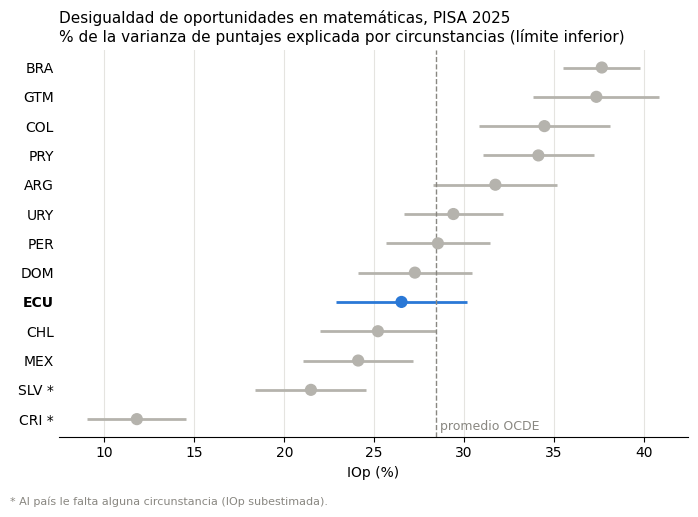

In [16]:
AZUL, GRIS, TINTA, TENUE = "#2a78d6", "#b5b3ad", "#0b0b0b", "#898781"

d = tabla[tabla["pais"] != "OCDE"].sort_values("iop")
etiquetas = [p + (" *" if inc else "") for p, inc in zip(d["pais"], d["incompleto"])]
y = np.arange(len(d))
colores = [AZUL if p == "ECU" else GRIS for p in d["pais"]]

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(100 * d["iop"], y, xerr=100 * 1.96 * d["iop_se"], fmt="none", ecolor=colores, elinewidth=2)
ax.scatter(100 * d["iop"], y, c=colores, s=60, zorder=3)
ax.axvline(100 * fila_ocde["iop"], color=TENUE, ls="--", lw=1)
ax.text(100 * fila_ocde["iop"], 0.01, " promedio OCDE", color=TENUE, fontsize=9,
        transform=ax.get_xaxis_transform(), va="bottom")
ax.set_yticks(y, etiquetas)
for t in ax.get_yticklabels():
    t.set_fontweight("bold" if t.get_text().startswith("ECU") else "normal")
ax.set_title("Desigualdad de oportunidades en matemáticas, PISA 2025\n"
             "% de la varianza de puntajes explicada por circunstancias (límite inferior)",
             loc="left", fontsize=11)
ax.set_xlabel("IOp (%)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
plt.figtext(0.01, -0.02, "* Al país le falta alguna circunstancia (IOp subestimada).", fontsize=8, color=TENUE)
plt.tight_layout()
plt.show()

## 10. ¿Qué circunstancia pesa más? (descomposición Fields - covarianzas)

Repartimos el R² entre las circunstancias, como en las ecuaciones 17–18 del paper. El aporte de cada circunstancia *j* es:

```latex
\theta_j = \frac{\mathrm{Cov}(X_j \hat\beta_j,\; y)}{\mathrm{Var}(y)}, \qquad \sum_j \theta_j = R^2
```

Es decir, cuánto se mueve el puntaje junto con la parte predicha por esa circunstancia. Los aportes **suman exactamente el R²**.

El paper advierte que estos aportes son **descriptivos, no causales**: los coeficientes individuales pueden estar sesgados.

Lo calculamos sin errores estándar (es descriptivo) y promediando los 10 PV.

In [17]:
def descomponer(pais):
    fila = (est["CNT"] == pais).to_numpy()
    X = X_all[fila].astype("float64")
    Y = est.loc[fila, PV].to_numpy("float64")
    w = est.loc[fila, PESO].to_numpy("float64")
    sw = np.sqrt(w)[:, None]
    beta = np.linalg.lstsq(X * sw, Y * sw, rcond=None)[0]
    vy = var_w(Y, w)
    mu_y = (w @ Y) / w.sum()
    aportes = {}
    for g, idx in COLS_GRUPO.items():
        parte = X[:, idx] @ beta[idx]                       # parte predicha por la circunstancia
        mu_p = (w @ parte) / w.sum()
        cov = (w @ ((parte - mu_p) * (Y - mu_y))) / w.sum()
        aportes[g] = (cov / vy).mean()                      # promedio de los 10 PV
    return aportes


desc = pd.DataFrame({p: descomponer(p) for p in iop["pais"]}).T
desc["total"] = desc.sum(axis=1)

# Control: la suma de aportes debe ser ≈ IOp (diferencias mínimas por las columnas sin variación)
control = desc["total"].round(3).rename("suma aportes").to_frame().join(iop.set_index("pais")["iop"].round(3))
control[control.index.isin(LATAM)].dropna()

,suma aportes,iop
BRA,0.377,0.377
GTM,0.374,0.374
COL,0.345,0.345
PRY,0.341,0.341
ARG,0.317,0.317
URY,0.294,0.294
PER,0.285,0.285
DOM,0.273,0.273
ECU,0.265,0.265
CHL,0.252,0.252


In [18]:
(desc.loc["ECU"].drop("total") / desc.loc["ECU", "total"] * 100).round(1).sort_values(ascending=False)

Bienes del hogar           23.0
Educación padre/tutor 2    19.9
Ocupación padre/tutor 1    19.1
Posesiones culturales      11.9
Educación padre/tutor 1    11.7
Zona de la escuela          7.9
Libros en casa              3.7
Sexo                        2.9
Migración                   0.7
Idioma en casa             -0.8
Name: ECU, dtype: float64

### Gráfico 2: el aporte de cada familia de circunstancias

Barras apiladas: el largo total es la IOp; cada color es una familia de circunstancias.

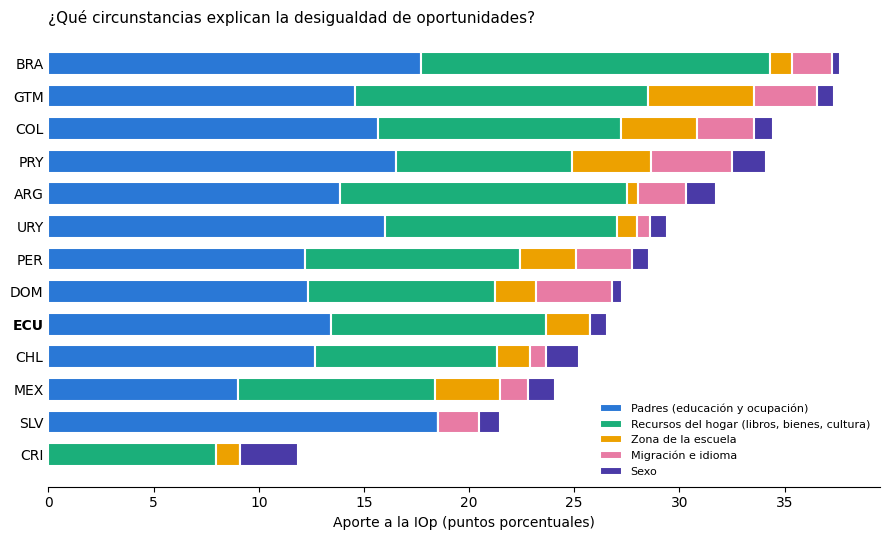

Padres (educación y ocupación)                  13.4
Recursos del hogar (libros, bienes, cultura)    10.2
Zona de la escuela                               2.1
Sexo                                             0.8
Migración e idioma                              -0.0
Name: ECU, dtype: float64

In [19]:
fam = pd.DataFrame({f: desc[gs].sum(axis=1) for f, gs in FAMILIAS.items()}) * 100
fam_lat = fam.loc[[p for p in tabla["pais"] if p in fam.index]].iloc[::-1]

COLORES_FAM = ["#2a78d6", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
fig, ax = plt.subplots(figsize=(9, 5.5))
izq = np.zeros(len(fam_lat))
for (familia, valores), color in zip(fam_lat.items(), COLORES_FAM):
    ax.barh(range(len(fam_lat)), valores.clip(lower=0), left=izq, color=color,
            edgecolor="white", linewidth=1.5, height=0.7, label=familia)
    izq += valores.clip(lower=0).to_numpy()
ax.set_yticks(range(len(fam_lat)), fam_lat.index)
for t in ax.get_yticklabels():
    t.set_fontweight("bold" if t.get_text() == "ECU" else "normal")
ax.set_xlabel("Aporte a la IOp (puntos porcentuales)")
ax.set_title("¿Qué circunstancias explican la desigualdad de oportunidades?", loc="left", fontsize=11)
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

fam.loc["ECU"].round(1).sort_values(ascending=False)

En 2006, el paper encontró que **libros en casa** y la **educación de los padres** eran lo que más pesaba, y el **sexo** casi nada.

## 11. Comparación con Ferreira y Gignoux (PISA 2006)

Copiamos de la **tabla 4 del paper** la IOp en matemáticas de 2006 y la comparamos con la nuestra de 2025.

La comparación es **orientativa**: las circunstancias no son idénticas (padre/tutor en vez de padre/madre, sin lavavajillas, etc.) y en 2006 las preguntas eran otras.

In [20]:
FG_2006 = {   # IOp en matemáticas, PISA 2006 (Ferreira y Gignoux, 2014, tabla 4)
    "AZE": .044, "HKG": .154, "IDN": .237, "ISR": .206, "JPN": .203, "JOR": .272, "KOR": .209,
    "KGZ": .306, "MAC": .102, "QAT": .254, "RUS": .165, "TAP": .275, "THA": .230, "TUN": .273,
    "TUR": .241, "ARG": .315, "BRA": .318, "CHL": .330, "COL": .216, "MEX": .261, "URY": .245,
    "AUS": .153, "CAN": .211, "NZL": .241, "USA": .279, "BGR": .331, "CZE": .268, "EST": .206,
    "HRV": .222, "HUN": .326, "LTU": .279, "LVA": .201, "MNE": .223, "POL": .241, "ROU": .313,
    "SRB": .276, "SVK": .317, "SVN": .263, "AUT": .300, "BEL": .329, "CHE": .282, "DEU": .351,
    "DNK": .219, "ESP": .239, "FIN": .179, "FRA": .335, "GBR": .258, "GRC": .228, "IRL": .235,
    "ISL": .167, "ITA": .178, "LIE": .323, "LUX": .291, "NLD": .271, "NOR": .195, "PRT": .274,
    "SWE": .233,
}

comp = iop.set_index("pais")[["iop", "latam", "incompleto"]].join(pd.Series(FG_2006, name="iop_2006"), how="inner")
comp["cambio"] = comp["iop"] - comp["iop_2006"]
print(f"Países comparables: {len(comp)}")
comp[comp["latam"]].round(3)

Países comparables: 54


,iop,latam,incompleto,iop_2006,cambio
BRA,0.377,True,False,0.318,0.059
COL,0.345,True,False,0.216,0.129
ARG,0.317,True,False,0.315,0.002
URY,0.294,True,False,0.245,0.049
CHL,0.252,True,False,0.330,-0.078
MEX,0.241,True,False,0.261,-0.020


### Gráfico 3: 2006 vs. 2025

Cada punto es un país. **Sobre la diagonal** = la desigualdad de oportunidades **subió**; **debajo** = **bajó**. América Latina en azul.

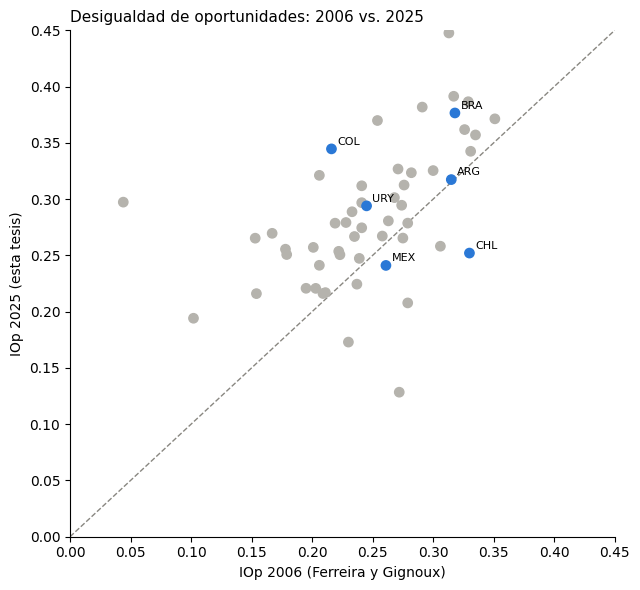

Correlación 2006–2025: 0.51
Países donde subió: 45 de 54


In [21]:
fig, ax = plt.subplots(figsize=(6.5, 6))
lim = [0, 0.45]
ax.plot(lim, lim, color=TENUE, lw=1, ls="--")
color = [AZUL if l else GRIS for l in comp["latam"]]
ax.scatter(comp["iop_2006"], comp["iop"], c=color, s=45, zorder=3)
for p, r in comp[comp["latam"]].iterrows():
    ax.annotate(p, (r["iop_2006"], r["iop"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("IOp 2006 (Ferreira y Gignoux)")
ax.set_ylabel("IOp 2025 (esta tesis)")
ax.set_title("Desigualdad de oportunidades: 2006 vs. 2025", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Correlación 2006–2025: {comp[['iop', 'iop_2006']].corr().iloc[0, 1]:.2f}")
print(f"Países donde subió: {(comp['cambio'] > 0).sum()} de {len(comp)}")

## 12. ¿La IOp depende del puntaje promedio? (hallazgo clave del paper)

Ferreira y Gignoux encontraron que la IOp **no se correlaciona** con el puntaje medio: un país puede rendir alto y ser injusto, o al revés. ¿Se mantiene en 2025?

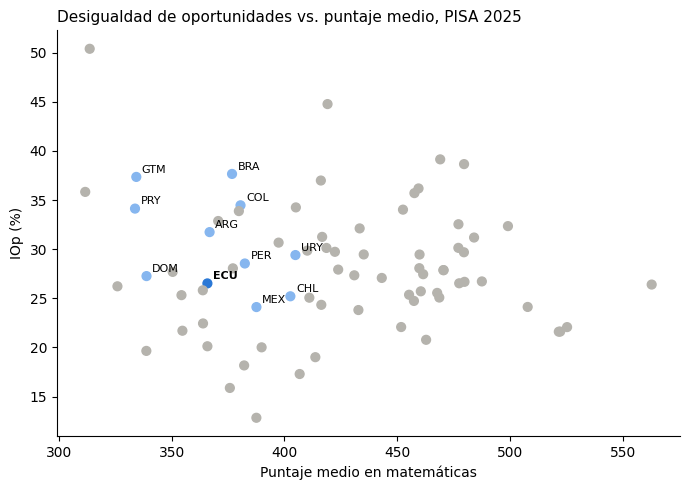

Correlación IOp–puntaje medio: -0.09  (cerca de 0 = se confirma el hallazgo del paper)


In [22]:
ok = iop[~iop["incompleto"]]
fig, ax = plt.subplots(figsize=(7, 5))
color = [AZUL if p == "ECU" else ("#86b6ef" if l else GRIS) for p, l in zip(ok["pais"], ok["latam"])]
ax.scatter(ok["media"], 100 * ok["iop"], c=color, s=40, zorder=3)
for _, r in ok[ok["latam"]].iterrows():
    ax.annotate(r["pais"], (r["media"], 100 * r["iop"]), xytext=(4, 3), textcoords="offset points", fontsize=8,
                fontweight="bold" if r["pais"] == "ECU" else "normal")
ax.set_xlabel("Puntaje medio en matemáticas")
ax.set_ylabel("IOp (%)")
ax.set_title("Desigualdad de oportunidades vs. puntaje medio, PISA 2025", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

r = ok[["media", "iop"]].corr().iloc[0, 1]
print(f"Correlación IOp–puntaje medio: {r:.2f}  (cerca de 0 = se confirma el hallazgo del paper)")

## 13. Guardar resultados

Guardamos la tabla por país (con la descomposición).

In [23]:
resultado = iop.set_index("pais").join(fam.add_prefix("aporte_")).join(pd.Series(FG_2006, name="iop_2006"))
resultado.to_csv(SALIDA / "paso3_iop_mco_por_pais.csv")
print("Guardado:", SALIDA / "paso3_iop_mco_por_pais.csv")

Guardado: c:\Users\pauls\Desktop\Yachay\Pisa\datos\resultados\paso3_iop_mco_por_pais.csv
